<div style="border:1px solid #d8e2ef; border-radius:18px; padding:26px 30px; background:#ffffff;">
  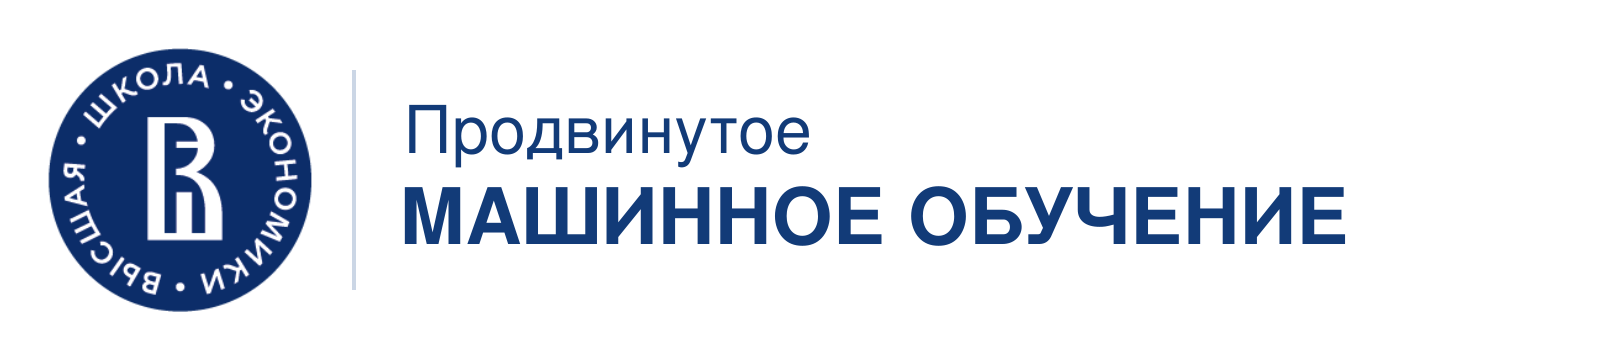

# Бонусное задание №3
## Градиентный бустинг: геометрия и функция потерь
</div>


Два небольших задания по лекции №4. Используем готовый бустинг из `sklearn`.

**Ваша работа:** в первом задании изменить глубину дерева и объяснить рисунки; во втором — вывести простую производную и дописать одну функцию. Обучение моделей и построение графиков уже подготовлены.

**Что сдать:** ноутбук с графиками для двух глубин, реализованной функцией и короткими ответами на вопросы. Достаточно 2–3 предложений на каждый вопрос.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.tree import plot_tree
from IPython.display import display

SEED = 42
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})


## 1. Всегда ли дерево делит пространство на две области? ($0,5$ балла)

У объектов два признака: $x_1$ и $x_2$. Построим ансамбль из **трёх деревьев** для квадратичной потери. На каждом шаге новое дерево обучается исправлять ошибки текущего ансамбля.

**Что сделать:**

1. Запустите готовую ячейку визуализации ниже.
2. Запустите `show_boosting(depth=1)` и рассмотрите все три шага.
3. Во второй ячейке вызова замените глубину 1 на 2 и запустите её. Сохраните оба результата.

**Как читать рисунок:** слева — поправка нового дерева **до** умножения на learning rate; чёрные линии показывают его разбиения. Справа — прогноз ансамбля после добавления этого дерева. Это разные величины:
$$F_m(x)=F_{m-1}(x)+0.5\,T_m(x).$$
Число листьев и выбранные пороги появятся в таблице. Код визуализации изменять не нужно.


In [2]:
#@title Готовая визуализация: выполните эту ячейку, дописывать её не нужно.
rng = np.random.default_rng(SEED)
X = rng.uniform(-1, 1, (240, 2))
y = 3.0 * (X[:, 0] > 0) + 2.0 * (X[:, 1] > 0.15)
axis = np.linspace(-1, 1, 180)
g1, g2 = np.meshgrid(axis, axis)
grid = np.column_stack([g1.ravel(), g2.ravel()])


def draw_splits(ax, tree):
    # Рисуем каждую границу только внутри соответствующего узла.
    t = tree.tree_
    def visit(node, x0, x1, y0, y1):
        if t.children_left[node] == -1:
            return
        feature, threshold = t.feature[node], t.threshold[node]
        if feature == 0:
            ax.plot([threshold, threshold], [y0, y1], 'k-', lw=1)
            visit(t.children_left[node], x0, threshold, y0, y1)
            visit(t.children_right[node], threshold, x1, y0, y1)
        else:
            ax.plot([x0, x1], [threshold, threshold], 'k-', lw=1)
            visit(t.children_left[node], x0, x1, y0, threshold)
            visit(t.children_right[node], x0, x1, threshold, y1)
    visit(0, -1, 1, -1, 1)


def show_boosting(depth):
    model = GradientBoostingRegressor(
        loss='squared_error', n_estimators=3, max_depth=depth,
        learning_rate=0.5, random_state=SEED,
    ).fit(X, y)
    stages = list(model.staged_predict(grid))
    trees = model.estimators_[:, 0]
    corrections = [tree.predict(grid) for tree in trees]
    bound = max(np.abs(values).max() for values in corrections)
    fig, axes = plt.subplots(3, 2, figsize=(9, 10), constrained_layout=True)
    rows = []
    for m, (tree, correction, prediction) in enumerate(zip(trees, corrections, stages)):
        for col, (values, title) in enumerate([
            (correction, f'Шаг {m+1}: новое дерево, листьев {tree.get_n_leaves()}'),
            (prediction, f'Шаг {m+1}: весь ансамбль'),
        ]):
            ax = axes[m, col]
            im = ax.pcolormesh(g1, g2, values.reshape(g1.shape), shading='auto',
                cmap='coolwarm' if col == 0 else 'viridis',
                vmin=-bound if col == 0 else 0, vmax=bound if col == 0 else 5)
            ax.set(xlabel='$x_1$', ylabel='$x_2$', title=title, aspect='equal')
            fig.colorbar(im, ax=ax, shrink=0.7)
        draw_splits(axes[m, 0], tree)
        t = tree.tree_
        nodes = np.flatnonzero(t.children_left != -1)
        rows.append({'Шаг': m+1, 'Листьев нового дерева': tree.get_n_leaves(),
            'Разбиения': '; '.join(f'x{t.feature[j]+1} <= {t.threshold[j]:.3f}' for j in nodes)})
    fig.suptitle(f'max_depth = {depth}', fontsize=14)
    plt.show()
    display(pd.DataFrame(rows))
    if depth == 2:
        fig, ax = plt.subplots(figsize=(10, 4))
        plot_tree(trees[0], feature_names=['x1', 'x2'], impurity=False,
                  filled=True, rounded=True, precision=2, ax=ax)
        ax.set_title('Первое дерево глубины 2: сравните узлы с областями на плоскости')
        plt.tight_layout()
        plt.show()
    return model


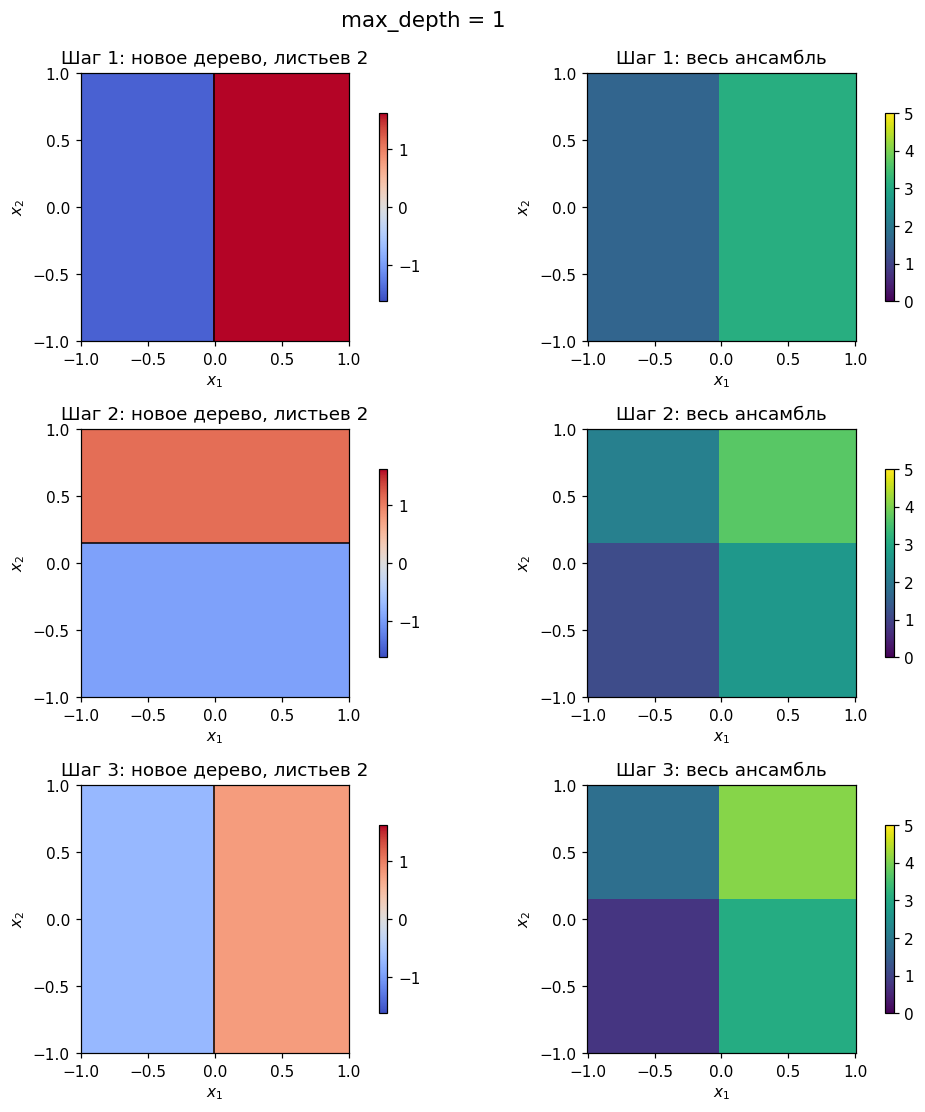

,Шаг,Листьев нового дерева,Разбиения
0,1,2,x1 <= -0.007
1,2,2,x2 <= 0.152
2,3,2,x1 <= -0.007


In [3]:
model_depth1 = show_boosting(depth=1)


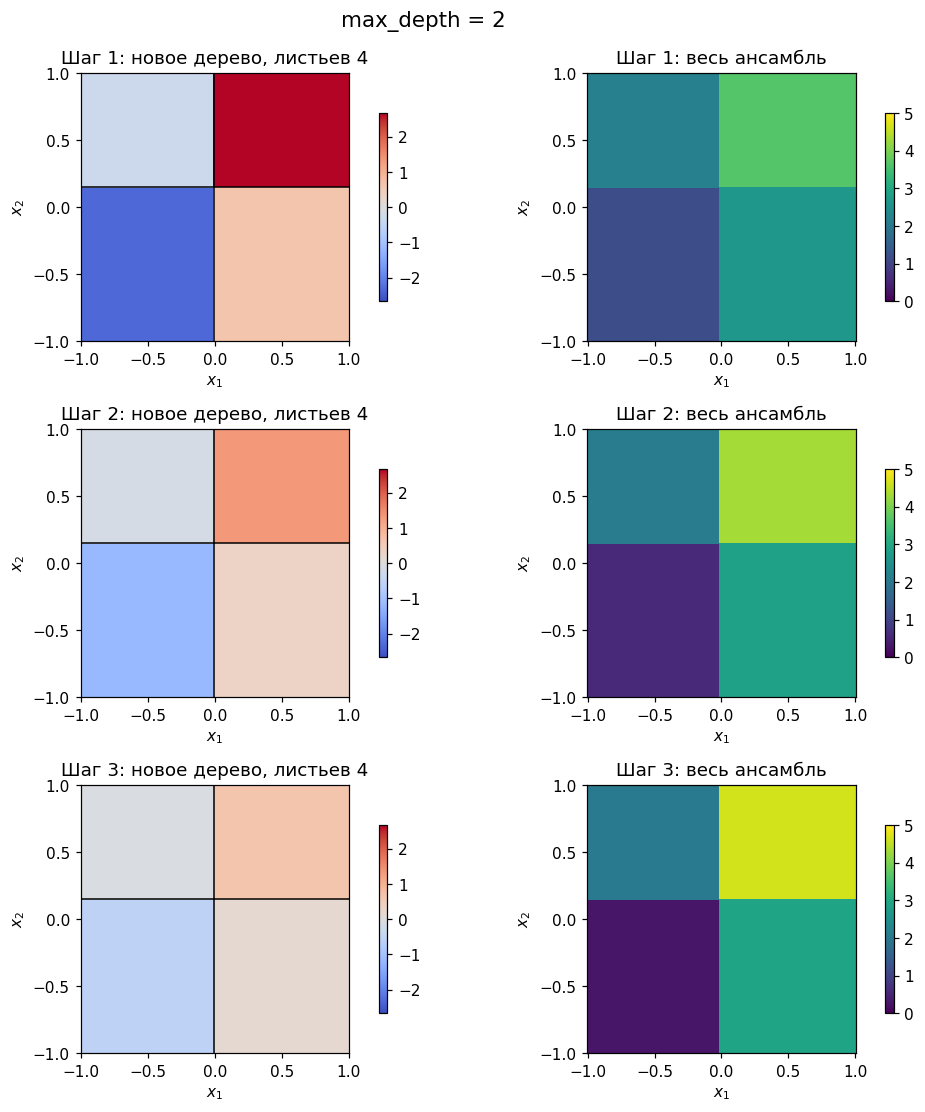

,Шаг,Листьев нового дерева,Разбиения
0,1,4,x1 <= -0.007; x2 <= 0.148; x2 <= 0.154
1,2,4,x1 <= -0.007; x2 <= 0.148; x2 <= 0.154
2,3,4,x1 <= -0.007; x2 <= 0.148; x2 <= 0.154


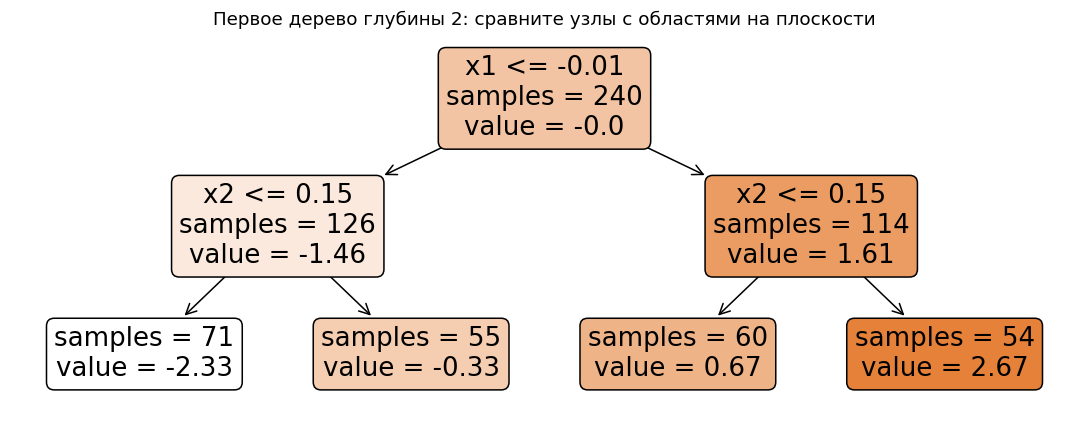

In [4]:
# Измените только depth на 2 и запустите эту ячейку.
model_depth2 = show_boosting(depth=2)


**Ответьте по рисункам и таблицам:**

На лекции мы с вами обсудили, что в нашем случае (когда используем решающие пни, как базовые модели) на каждом шаге деревом (пнем) будет выделяться максимум 2 области (2 листа). Для решающих пней, как базовых моделей, это верно всегда - максимум 2 листа. Но какие есть случаи, при которых мы столкнемся с более сложным разбиением на каждом шаге? Давайте для этого поподробнее ответим на следующие вопросы, а в конце сделайте общий вывод-заключение к данному эксперименту.

1. Сколько областей выделяет первое дерево при глубине 1 и при глубине 2? Почему у бинарного дерева может быть больше двух листьев?
2. Как направлены границы относительно осей? Может ли одно такое разбиение узла провести наклонную прямую?
3. Обязательно ли следующее дерево выбирает новые границы? Найдите повторение или изменение признака и порога в своих таблицах.
4. Чем рисунок нового дерева отличается от рисунка всего ансамбля? Используйте формулу обновления из условия.

**Ваши ответы:** …

1. При глубине 1 первое дерево выделяет 2 области. В таблице листьев 2, разрез один, x1 <= -0.007. На левом рисунке шага 1 вертикальная стенка около нуля, слева синяя поправка, справа красная. При глубине 2 первое дерево выделяет 4 области. В таблице листьев 4, разрезы x1 <= -0.007, затем x2 <= 0.148 и x2 <= 0.154. На схеме дерева это корень x1 <= -0.01 на 240 точках, левая часть 126 точек со значением $-1.46$, правая 114 точек со значением $1.61$, и четыре листа: 71 точка со значением $-2.33$, 55 со значением $-0.33$, 60 со значением $0.67$, 54 со значением $2.67$. Бинарное дерево может иметь больше двух листьев, потому что глубина 2 разрешает второй вопрос уже в обеих частях. Максимум листьев равен $2^d$. При $d=1$ это 2, при $d=2$ это 4. Пень режет один раз, более глубокое дерево режет рекурсивно.
2. Границы параллельны осям. Разрез по $x_1$ даёт вертикальную линию, это шаг 1 и шаг 3 при глубине 1. Разрез по $x_2$ даёт горизонтальную линию, это шаг 2 около $0.15$. Одно разбиение узла не проводит наклонную прямую. CART ставит только предикат $x_j\le s$. Наклон появляется только как лесенка из нескольких осевых разрезов, не как один вопрос.
3. Новые границы не обязательны. При глубине 1 шаг 1 и шаг 3 совпали, оба x1 <= -0.007. Шаг 2 другой, x2 <= 0.152. На рисунке шаг 3 снова вертикальный, но цвета бледнее, чем на шаге 1, потому что остаток уже меньше. При глубине 2 все три строки таблицы одинаковые, x1 <= -0.007; x2 <= 0.148; x2 <= 0.154. Причина в множителе $0.5$. Одна поправка закрывает только половину остатка, знак в тех же четырёх прямоугольниках сохраняется, следующий шаг берёт тот же $(j,s)$.
4. Левый рисунок это $T_m$ до умножения на $0.5$, чёрные линии это его разрезы. Правый рисунок это весь ансамбль $F_m=F_{m-1}+0.5\,T_m$. На шаге 1 при глубине 1 слева две полосы около $-1$ и $1$, справа уже две полосы около $1$ и $3$, потому что к поправке прибавлена инициализация. На шаге 2 слева одна горизонталь, справа уже четыре прямоугольника. На шаге 3 слева снова вертикаль, справа четыре цвета расходятся сильнее, нижний левый темнее, верхний правый светлее. Новое дерево не помнит прошлые шаги. Ансамбль их складывает, поэтому цвет справа не совпадает с цветом слева.

## 2. А если ошибка измеряется модулем? ($0,5$ балла)

Для квадратичной потери $L(y,F)=\frac12(y-F)^2$ псевдоостаток равен обычной ошибке $y-F$. Теперь возьмём **абсолютную ошибку**:
$$L(y,F)=|y-F|.$$

**Что сделать:**

1. Найдите $r=-\frac{\partial L}{\partial F}$ отдельно при $y>F$ и $y<F$. Подсказка: раскройте модуль в каждом случае и продифференцируйте **по $F$**.
2. Реализуйте функцию ниже по полученной формуле. При $y=F$ производной нет; для этого упражнения принимаем $r=0$ — допустимое значение отрицательного субградиента. Доказывать это не требуется.
3. Запустите проверки, таблицу и готовый эксперимент с двумя функциями потерь.

**Ваш вывод производной:** …

При $y>F$ модуль раскрывается как $L=y-F$, поэтому $\partial L/\partial F=-1$ и $r=1$. При $y<F$ модуль раскрывается как $L=F-y$, поэтому $\partial L/\partial F=1$ и $r=-1$. При $y=F$ берём $r=0$. Вместе
$$r=-\frac{\partial L}{\partial F}=\mathrm{sign}(y-F).$$
Для квадратичной потери $L=\frac12(y-F)^2$ та же операция даёт $r=y-F$. Знак у обеих потерь один, величина нет.

In [13]:
def absolute_pseudo(y, prediction):
    y = np.asarray(y, dtype=float)
    prediction = np.asarray(prediction, dtype=float)
    return np.sign(y - prediction)

ready = absolute_pseudo([3., -2., 1.], [1., 1., 1.]) is not None
if ready:
    assert np.allclose(absolute_pseudo([3., -2., 1.], [1., 1., 1.]), [1., -1., 0.])
    assert np.allclose(absolute_pseudo([20., -50.], [0., 0.]), [1., -1.])
    print("Обе проверки пройдены, вы молодец!! Great job:)")
    errors = np.array([-8., -2., -0.3, 0., 0.3, 2., 8.])
    display(pd.DataFrame({
        "Обычная ошибка y-F": errors,
        "Псевдоостаток: квадратичная потеря": errors,
        "Псевдоостаток: абсолютная потеря": absolute_pseudo(errors, np.zeros_like(errors)),
    }))
else:
    print("Сначала допишите absolute_pseudo и снова запустите ячейку.")

Обе проверки пройдены, вы молодец!! Great job:)


,Обычная ошибка y-F,Псевдоостаток: квадратичная потеря,Псевдоостаток: абсолютная потеря
0,-8.0,-8.0,-1.0
1,-2.0,-2.0,-1.0
2,-0.3,-0.3,-1.0
3,0.0,0.0,0.0
4,0.3,0.3,1.0
5,2.0,2.0,1.0
6,8.0,8.0,1.0


**Готовый эксперимент.** Есть плавная зависимость и несколько сильно завышенных откликов — выбросов. Обучим два ансамбля на одинаковых данных и с одинаковыми настройками деревьев; поменяем только loss.

Ваша функция выше нужна для изучения псевдоостатков. Модели ниже используют встроенные функции потерь `sklearn`; библиотека сама подбирает соответствующие начальные константы и поправки в листьях. Реализовывать бустинг вручную не нужно.

На графике чёрная линия — известная истинная зависимость, точки — обучающие наблюдения. Это наглядный эксперимент, а не оценка качества на независимом тесте.


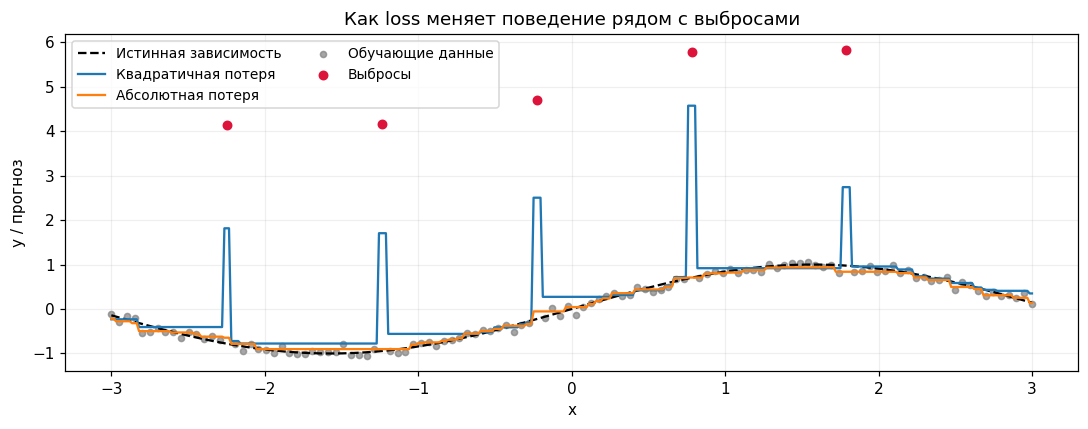

In [8]:
rng = np.random.default_rng(SEED)
x = np.linspace(-3, 3, 120)
y_signal = np.sin(x)
y_observed = y_signal + rng.normal(0, 0.1, len(x))
outliers = np.array([15, 35, 55, 75, 95])
y_observed[outliers] += 5
x_grid = np.linspace(-3, 3, 400)

fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(x, y_observed, s=16, color='gray', alpha=0.7, label='Обучающие данные')
ax.scatter(x[outliers], y_observed[outliers], s=30, color='crimson', label='Выбросы')
ax.plot(x_grid, np.sin(x_grid), 'k--', label='Истинная зависимость')

loss_models = {}
for loss, name in [('squared_error', 'Квадратичная потеря'),
                   ('absolute_error', 'Абсолютная потеря')]:
    model = GradientBoostingRegressor(
        loss=loss, n_estimators=50, max_depth=2,
        learning_rate=0.1, random_state=SEED,
    ).fit(x.reshape(-1, 1), y_observed)
    loss_models[loss] = model
    ax.plot(x_grid, model.predict(x_grid.reshape(-1, 1)), label=name)

ax.set(xlabel='x', ylabel='y / прогноз', title='Как loss меняет поведение рядом с выбросами')
ax.legend(ncol=2, fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


**Ответьте по таблице и графику:**

1. Как различаются псевдоостатки для ошибок 2 и 8 при двух потерях? Что сообщает их знак, а что — величина?
2. Какая модель в этом опыте сильнее отклоняется в сторону выбросов? Свяжите наблюдение с выведенной производной.
3. Согласны ли вы с фразой «в градиентном бустинге новое дерево всегда учится предсказывать обычные ошибки `y − F`»? Объясните на примере двух рассмотренных потерь.

**Ваши ответы:** …


1. Для ошибок 2 и 8 квадратичный псевдоостаток равен 2 и 8. Абсолютный равен 1 и 1. Знак говорит направление. Плюс значит $y>F$, ансамбль занизил ответ, следующее дерево должно поднять прогноз. Минус значит $y<F$. Величина у квадрата растёт вместе с ошибкой, 8 в четыре раза сильнее 2. У модуля величина обрезана до 1, поэтому ошибка 8 тянет дерево не сильнее ошибки 2 и не сильнее ошибки 0.3. В таблице это видно по строкам 5 и 6.
2. Сильнее к выбросам уходит квадратичная потеря. На графике синяя кривая даёт пять узких пиков к красным точкам, самый высокий около 4.6 при $x\approx 0.8$. Оранжевая кривая остаётся на чёрном пунктире $\sin x$ и к красным точкам не идёт. Это следствие производной. Выброс даёт остаток около 5. Для квадрата $r\approx 5$, для модуля $r=1$. Печать на тех же данных: средний прогноз квадрата на пяти выбросах равен 2.67, у модуля равен $-0.01$. MAE на обычных точках у квадрата 0.120, у модуля 0.053.
3. Не согласен. Новое дерево учится на псевдоостатке $r=-\partial L/\partial F$, а не всегда на $y-F$. Для $L=\frac12(y-F)^2$ они совпадают, поэтому ошибка 8 входит в дерево как 8 и на графике поднимает синий пик. Для $L=|y-F|$ псевдоостаток равен $\mathrm{sign}(y-F)$, ошибка 8 входит как 1, и оранжевая кривая выброс почти не замечает.

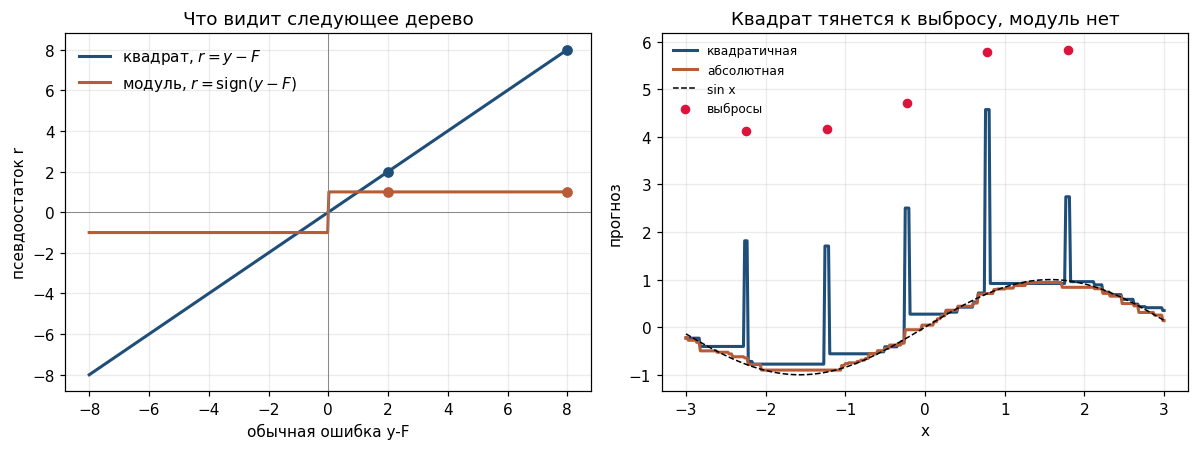

In [12]:
err = np.linspace(-8, 8, 400)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].plot(err, err, color="#1f4e79", lw=2, label=r"квадрат, $r=y-F$")
axes[0].plot(err, np.sign(err), color="#b85c38", lw=2, label=r"модуль, $r=\mathrm{sign}(y-F)$")
axes[0].axhline(0, color="0.5", lw=0.6)
axes[0].axvline(0, color="0.5", lw=0.6)
axes[0].scatter([2, 8], [2, 8], color="#1f4e79", zorder=3)
axes[0].scatter([2, 8], [1, 1], color="#b85c38", zorder=3)
axes[0].set(xlabel="обычная ошибка y-F", ylabel="псевдоостаток r", title="Что видит следующее дерево")
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.25)

for loss, name, color in [
    ("squared_error", "квадратичная", "#1f4e79"),
    ("absolute_error", "абсолютная", "#b85c38"),
]:
    pred = loss_models[loss].predict(x_grid.reshape(-1, 1))
    axes[1].plot(x_grid, pred, color=color, lw=2, label=name)
axes[1].plot(x_grid, np.sin(x_grid), "k--", lw=1, label="sin x")
axes[1].scatter(x[outliers], y_observed[outliers], s=28, color="crimson", zorder=3, label="выбросы")
axes[1].set(xlabel="x", ylabel="прогноз", title="Квадрат тянется к выбросу, модуль нет")
axes[1].legend(frameon=False, fontsize=8)
axes[1].grid(alpha=0.25)
fig.tight_layout()
plt.show()